# Прогноз посещаемости матчей АПЛ: данные и модели

Ноутбук показывает результаты системы: что загружено, насколько данным можно верить, как устроены признаки и как работают модели.
Весь код берётся из проекта (`backend/db`, `backend/pipeline`, `backend/ml`), поэтому цифры совпадают с рабочей системой.

**Как читать.** У каждого графика есть вопрос, на который он отвечает. Разделы:
1. Что загружено и как прошла загрузка
2. Можно ли верить данным о посещаемости
3. От чего зависит посещаемость
4. Признаки и проверка на утечку
5. Отбор признаков
6. Сравнение моделей
7. Прогноз против факта
8. Прогноз на ближайшие матчи
9. Выводы и ограничения

In [1]:
import json
import subprocess
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "backend"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sqlalchemy import text

from db.session import engine

SURFACE, INK, INK_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e3e2dd"
BLUE, ORANGE, AQUA, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#8b8a85"
COLORS = {"naive": GRAY, "hgb": BLUE, "rf": AQUA, "ridge": ORANGE}
LABELS = {"naive": "наивный (база)", "ridge": "линейная", "hgb": "бустинг", "rf": "случайный лес"}

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "text.color": INK, "font.size": 10, "axes.titlesize": 11, "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.8, "axes.axisbelow": True, "figure.dpi": 110,
})


def sql(query, **params):
    with engine.connect() as conn:
        return pd.read_sql(text(query), conn, params=params)


def thousands(value):
    return f"{value:,.0f}".replace(",", " ")

## 1. Что загружено и как прошла загрузка

*Вопрос: данные из трёх источников на месте, загрузка идёт без сбоев и не дублирует записи?*

In [2]:
totals = sql('''SELECT (SELECT count(*) FROM teams) AS клубов, (SELECT count(*) FROM matches) AS матчей,
                       (SELECT count(*) FROM news_articles) AS новостей, (SELECT count(*) FROM ingest_runs) AS запусков_загрузки''')
display(totals)
journal = sql('''SELECT id, source AS источник, status AS статус, rows_fetched AS получено, rows_inserted AS вставлено,
                        rows_updated AS обновлено, rows_skipped AS без_изменений, rows_rejected AS отклонено
                 FROM ingest_runs ORDER BY id DESC LIMIT 9''')
display(journal)

,клубов,матчей,новостей,запусков_загрузки
0,46,10260,70,6


,id,источник,статус,получено,вставлено,обновлено,без_изменений,отклонено
0,6,bbc_rss,success,75,0,0,75,0
1,5,football_data,success,760,0,0,760,0
2,4,csv_history,success,9880,0,0,9880,0
3,3,bbc_rss,success,75,70,0,5,0
4,2,football_data,success,760,380,380,0,0
5,1,csv_history,success,9880,9880,0,0,0


В журнале видно главное свойство загрузки: **повторный запуск ничего не вставляет и не обновляет** (вставлено 0, обновлено 0, всё «без изменений»).
Это и есть идемпотентность. Проверки качества, которые не прошли в последней загрузке, показывают реальные особенности данных:

In [3]:
failed = sql('''SELECT check_name AS проверка, severity AS важность, left(details::text, 120) AS детали
                FROM dq_checks WHERE NOT passed AND run_id = (SELECT max(id) FROM ingest_runs WHERE source = 'football_data')''')
display(failed)

,проверка,важность,детали
0,attendance_consistent_with_stadium,warn,"{""seasons"": [{""season"": 2000, ""comparable"": 33..."
1,fanless_matches,warn,"{""by_season"": [{""season"": 2019, ""matches"": 6},..."


## 2. Можно ли верить данным о посещаемости

*Вопрос: в каких сезонах посещаемость в CSV согласуется с реальностью и на каких сезонах можно обучать модель?*

Для каждого сезона считается корреляция посещаемости матча с типичной посещаемостью его стадиона (по остальным сезонам).
Если данные верны, стадион на 60 тысяч не может собрать 20 тысяч без причины, и корреляция высокая.

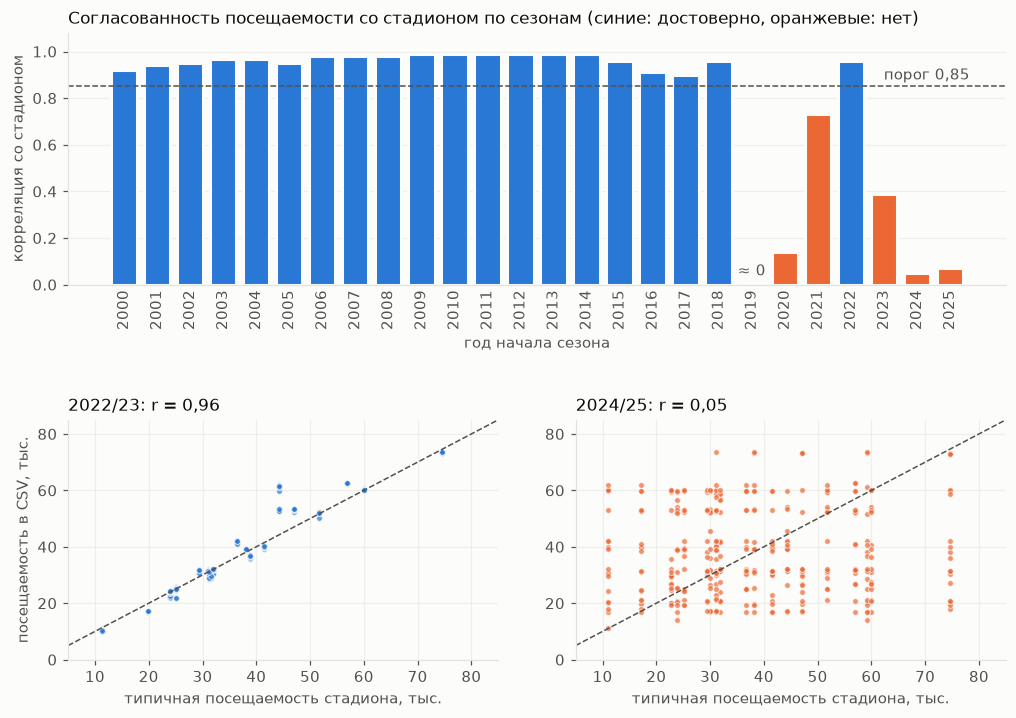

,статус,матчей
0,ok,7600
1,suspect,1917
2,missing,380
3,fanless,363


In [4]:
from pipeline.quality import MIN_CORRELATION, season_consistency

rows = sql("SELECT season, stadium, attendance FROM matches")
stats = pd.DataFrame(season_consistency(rows)).set_index("season")["correlation"].reindex(range(2000, 2026)).fillna(0)
played = rows[(rows.attendance > 0) & rows.stadium.notna()]


def stadium_frame(season):
    baseline = played[played.season != season].groupby("stadium").attendance.median()
    group = played[played.season == season]
    return group.assign(typical=group.stadium.map(baseline)).dropna(subset=["typical"])


fig = plt.figure(figsize=(11, 7.4))
grid = fig.add_gridspec(2, 2, height_ratios=[1.05, 1], hspace=0.55, wspace=0.18)
ax = fig.add_subplot(grid[0, :])
colors = [BLUE if v >= MIN_CORRELATION else ORANGE for v in stats]
ax.bar([str(s) for s in stats.index], stats.values, color=colors, edgecolor=SURFACE, linewidth=2)
ax.axhline(MIN_CORRELATION, color=INK_2, linestyle="--", linewidth=1)
ax.text(len(stats) - 0.4, MIN_CORRELATION + 0.03, f"порог {MIN_CORRELATION}".replace(".", ","), ha="right", color=INK_2)
ax.text(list(stats.index).index(2019), 0.04, "≈ 0", ha="center", color=INK_2)
ax.set_ylim(0, 1.08)
ax.set_ylabel("корреляция со стадионом")
ax.set_xlabel("год начала сезона")
ax.tick_params(axis="x", labelrotation=90, length=0)
ax.grid(axis="x", visible=False)
ax.set_title("Согласованность посещаемости со стадионом по сезонам (синие: достоверно, оранжевые: нет)")
for slot, season in enumerate((2022, 2024)):
    sub = fig.add_subplot(grid[1, slot])
    frame = stadium_frame(season)
    color = BLUE if stats[season] >= MIN_CORRELATION else ORANGE
    sub.scatter(frame.typical / 1000, frame.attendance / 1000, s=14, color=color, alpha=0.7, edgecolors=SURFACE, linewidths=0.6)
    sub.plot([5, 85], [5, 85], color=INK_2, linewidth=1, linestyle="--")
    sub.set_xlim(5, 85)
    sub.set_ylim(0, 85)
    sub.set_xlabel("типичная посещаемость стадиона, тыс.")
    if slot == 0:
        sub.set_ylabel("посещаемость в CSV, тыс.")
    sub.set_title(f"{season}/{str(season + 1)[2:]}: r = {stats[season]:.2f}".replace(".", ","))
plt.show()
status = sql("SELECT attendance_status AS статус, count(*) AS матчей FROM matches GROUP BY 1 ORDER BY 2 DESC")
display(status)

**Вывод.** Для сезонов 2019/20, 2021/22, 2023/24, 2024/25 и 2025/26 посещаемость в открытом CSV не связана со стадионом (справа внизу), другого источника по этим сезонам нет.
Система сама помечает такие матчи (`suspect`) и исключает их из обучения. Обучаемых матчей остаётся 7 600.

## 3. От чего зависит посещаемость

*Вопрос: как меняется посещаемость со временем, между клубами, по дням недели и в дерби?*
Здесь только матчи со статусом `ok`.

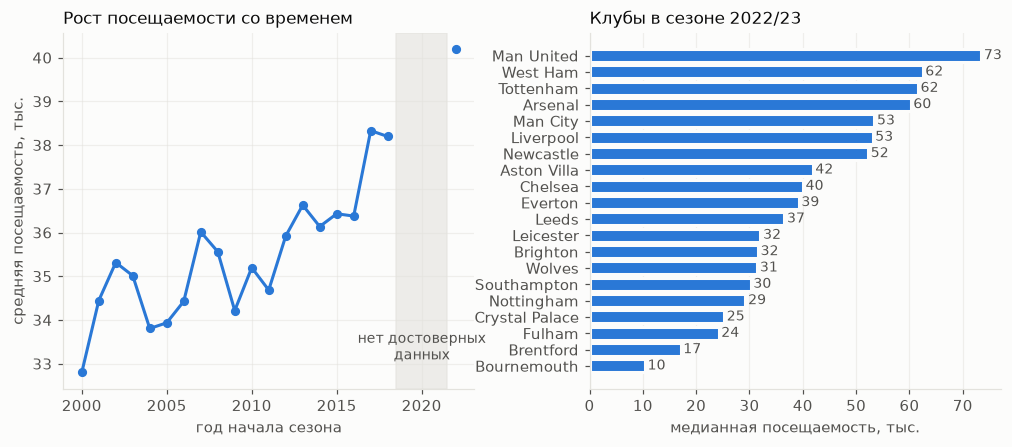

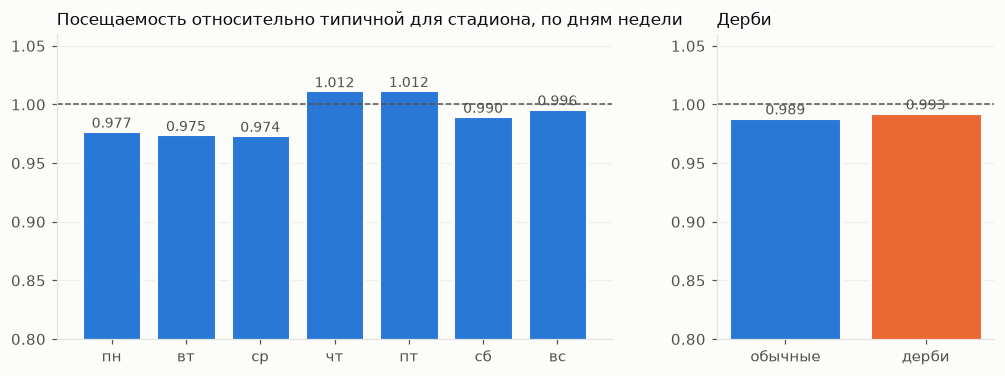

In [5]:
matches = sql('''SELECT m.season, m.match_date, m.attendance, m.attendance_status AS status, m.stadium, m.is_derby,
                        th.name AS home
                 FROM matches m JOIN teams th ON th.id = m.home_team_id''')
ok = matches[matches.status == "ok"].copy()
ok["relative"] = ok.attendance / ok.groupby("stadium").attendance.transform("median")
ok["weekday"] = pd.to_datetime(ok.match_date).dt.dayofweek

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"wspace": 0.28})
by_season = ok.groupby("season").attendance.mean().reindex(range(2000, 2023))
ax = axes[0]
ax.plot(by_season.index, by_season.values / 1000, color=BLUE, marker="o", markersize=5, linewidth=2)
ax.axvspan(2018.5, 2021.5, color=GRID, alpha=0.6)
ax.text(2020, by_season.min() / 1000 + 0.3, "нет достоверных\nданных", ha="center", color=INK_2, fontsize=9)
ax.set_ylabel("средняя посещаемость, тыс.")
ax.set_xlabel("год начала сезона")
ax.set_title("Рост посещаемости со временем")
clubs = ok[ok.season == 2022].groupby("home").attendance.median().sort_values() / 1000
ax = axes[1]
ax.barh(clubs.index, clubs.values, color=BLUE, edgecolor=SURFACE, linewidth=2)
for y, v in enumerate(clubs.values):
    ax.text(v + 0.5, y, f"{v:.0f}", va="center", color=INK_2, fontsize=9)
ax.set_xlabel("медианная посещаемость, тыс.")
ax.set_title("Клубы в сезоне 2022/23")
ax.grid(axis="y", visible=False)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"wspace": 0.25, "width_ratios": [2, 1]})
weekday = ok.groupby("weekday").relative.mean()
names = ["пн", "вт", "ср", "чт", "пт", "сб", "вс"]
ax = axes[0]
ax.bar([names[i] for i in weekday.index], weekday.values, color=BLUE, edgecolor=SURFACE, linewidth=2)
ax.axhline(1, color=INK_2, linestyle="--", linewidth=1)
for i, v in enumerate(weekday.values):
    ax.text(i, v, f"{v:.3f}", ha="center", va="bottom", fontsize=9, color=INK_2)
ax.set_ylim(0.8, 1.06)
ax.set_title("Посещаемость относительно типичной для стадиона, по дням недели")
ax.grid(axis="x", visible=False)
derby = ok.dropna(subset=["is_derby"]).groupby("is_derby").relative.mean()
ax = axes[1]
ax.bar(["обычные", "дерби"], [derby[False], derby[True]], color=[BLUE, ORANGE], edgecolor=SURFACE, linewidth=2)
ax.axhline(1, color=INK_2, linestyle="--", linewidth=1)
for i, v in enumerate([derby[False], derby[True]]):
    ax.text(i, v, f"{v:.3f}", ha="center", va="bottom", fontsize=9, color=INK_2)
ax.set_ylim(0.8, 1.06)
ax.set_title("Дерби")
ax.grid(axis="x", visible=False)
plt.show()

Посещаемость растёт со временем и сильно зависит от клуба (вместимости стадиона). Эффекты дня недели и дерби малы, в пределах 1–2 %:
стадионы заполнены почти независимо от матча. Это объясняет, почему простой прогноз по истории стадиона очень силён (раздел 6).

## 4. Признаки и проверка на утечку

*Вопрос: из чего состоят признаки и как доказано, что модель не «подглядывает» в будущее?*

In [6]:
from ml.dataset import FEATURE_GROUPS, load_dataset, trainable

with engine.connect() as conn:
    dataset = load_dataset(conn)
data = trainable(dataset)
display(pd.DataFrame([{"группа": g, "признаков": len(f), "признаки": ", ".join(f)} for g, f in FEATURE_GROUPS.items()]))
print("обучаемых матчей:", len(data))

,группа,признаков,признаки
0,calendar,5,"weekday, month, is_weekend, is_holiday_period,..."
1,context,1,is_derby
2,form,6,"h_ppg5, a_ppg5, h_gd5, a_gd5, rest_days_h, res..."
3,table,8,"h_played, a_played, h_season_ppg, a_season_ppg..."
4,attendance_history,7,"att_hist_n, att_last1, att_mean3, att_mean10, ..."
5,opponent_pull,1,away_pull
6,club,1,home_team_id
7,news,4,"h_news_count, a_news_count, h_news_sent, a_new..."


обучаемых матчей: 6686


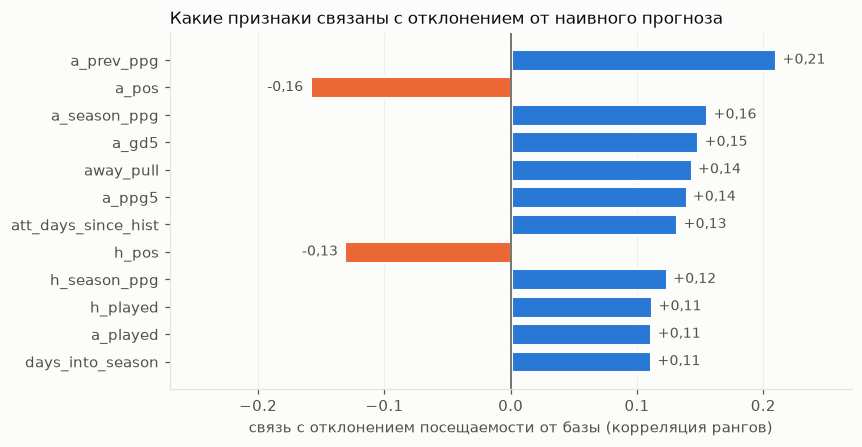

In [7]:
target = np.log(data.attendance / data.baseline).rank()
columns = [c for cols in FEATURE_GROUPS.values() for c in cols if data[c].nunique() > 1]
corr = pd.Series({c: data[c].rank().corr(target) for c in columns}).dropna()
top = corr.reindex(corr.abs().sort_values(ascending=False).index).head(12)[::-1]
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(top.index, top.values, color=[BLUE if v > 0 else ORANGE for v in top.values], edgecolor=SURFACE, linewidth=2)
for y, v in enumerate(top.values):
    ax.text(v + (0.005 if v > 0 else -0.005), y, f"{v:+.2f}".replace(".", ","), va="center",
            ha="left" if v > 0 else "right", fontsize=9, color=INK_2)
ax.axvline(0, color=INK_2, linewidth=1)
ax.set_xlim(-0.27, 0.27)
ax.set_xlabel("связь с отклонением посещаемости от базы (корреляция рангов)")
ax.set_title("Какие признаки связаны с отклонением от наивного прогноза")
ax.grid(axis="y", visible=False)
plt.show()

Сила команд (позиция в таблице и очки прошлого сезона) связана с отклонением сильнее остальных: сильные соперники привлекают зрителей.

**Проверка на утечку.** Тесты строят признаки по полной таблице и по таблице, из которой вырезано всё после даты матча, и требуют, чтобы они совпали.
Также проверяется, что исход самого матча и недостоверная посещаемость не влияют на признаки.

In [8]:
result = subprocess.run([sys.executable, "-m", "pytest", "-q", "--color=no", "tests/test_features.py"],
                        cwd=ROOT / "backend", capture_output=True, text=True)
print("тесты на утечку:", result.stdout.strip().splitlines()[-1])

тесты на утечку: 43 passed in 1.72s


## 5. Отбор признаков

*Вопрос: какие группы признаков действительно улучшают прогноз?*
Группы убираются по одной, пока качество (средняя ошибка в скользящей проверке) не начнёт ухудшаться.

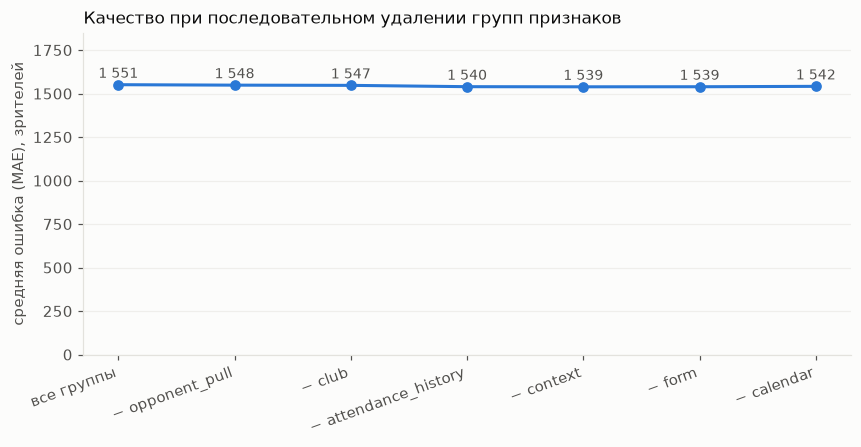

остались группы: ['table']
признаков: 8 -> h_played, a_played, h_season_ppg, a_season_ppg, h_pos, a_pos, h_prev_ppg, a_prev_ppg


In [9]:
selection = json.loads((ROOT / "backend/ml/selected_features.json").read_text())
points = [("все группы", selection["start_mae"])]
for step in selection["steps"]:
    if step["removed"]:
        points.append((f"− {step['removed']}", step["scores_without_group"][step["removed"]]))
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(range(len(points)), [p[1] for p in points], color=BLUE, marker="o", linewidth=2)
for i, (label, value) in enumerate(points):
    ax.text(i, value + 40, f"{value:,.0f}".replace(",", " "), ha="center", fontsize=9, color=INK_2)
ax.set_xticks(range(len(points)))
ax.set_xticklabels([p[0] for p in points], rotation=20, ha="right")
ax.set_ylim(0, 1850)
ax.set_ylabel("средняя ошибка (MAE), зрителей")
ax.set_title("Качество при последовательном удалении групп признаков")
ax.grid(axis="x", visible=False)
plt.show()
print("остались группы:", selection["groups"])
print("признаков:", len(selection["features"]), "->", ", ".join(selection["features"]))

Удаление почти любой группы практически не меняет ошибку (различия в пределах 1 %), остаётся только таблица, то есть сила играющих команд.
Это важный вывод: сверх «посещаемости в прошлых матчах» информативно мало что.

## 6. Сравнение моделей

*Вопрос: какая модель точнее и насколько лучше наивного прогноза?*

Наивный прогноз (база): средняя посещаемость последних 10 домашних матчей стадиона. Модели предсказывают поправку к нему.
Проверка во времени: каждый сезон 2010–2018 прогнозируется моделью, обученной только на прошлых сезонах.
Итоговый тест: сезон 2022/23, который в выборе модели не участвовал; его история признаков четырёхлетней давности, как у прогноза на 2026/27.

In [10]:
from ml.dataset import LAST_TRAIN_SEASON, TEST_SEASON, selected_features
from ml.estimators import MODEL_NAMES
from ml.validation import KEEP, cv_summary, fit_predict, metrics, walk_forward

features = selected_features(data)
cv_frames = {name: walk_forward(data, name, features) for name in MODEL_NAMES}
cv_metrics = {name: cv_summary(frame) for name, frame in cv_frames.items()}
train = data[data.season <= LAST_TRAIN_SEASON]
test = data[data.season == TEST_SEASON]
test_frames = {name: test[KEEP].assign(pred=fit_predict(train, test, name, features)) for name in MODEL_NAMES}
test_metrics = {name: metrics(frame) for name, frame in test_frames.items()}

COLUMNS = {"mae": "MAE, зрителей", "medae": "медианная ошибка", "rmse": "RMSE", "mape": "MAPE, %",
           "mae_pct_capacity": "ошибка, % вместимости", "within_5pct_capacity": "в пределах 5 %, % матчей"}


def table(results):
    frame = pd.DataFrame(results).T.loc[MODEL_NAMES, list(COLUMNS)].rename(columns=COLUMNS).round(2)
    frame.index = [LABELS[n] for n in frame.index]
    return frame


print("Скользящая проверка 2010–2018 (среднее по сезонам)")
display(table(cv_metrics))
print("Тест 2022/23")
display(table(test_metrics))

Скользящая проверка 2010–2018 (среднее по сезонам)


,"MAE, зрителей",медианная ошибка,RMSE,"MAPE, %","ошибка, % вместимости","в пределах 5 %, % матчей"
наивный (база),1523.55,550.89,3367.73,4.16,4.25,77.86
линейная,1685.68,849.84,3385.04,4.43,4.56,77.65
бустинг,1516.66,600.29,3329.59,4.09,4.21,79.78
случайный лес,1642.50,796.55,3355.80,4.40,4.53,77.33


Тест 2022/23


,"MAE, зрителей",медианная ошибка,RMSE,"MAPE, %","ошибка, % вместимости","в пределах 5 %, % матчей"
наивный (база),1472.51,634.20,2797.58,3.43,3.23,86.84
линейная,1708.50,864.21,2957.69,4.00,3.79,83.04
бустинг,1488.47,583.21,2806.23,3.45,3.25,83.63
случайный лес,1687.85,782.96,2967.61,3.92,3.70,82.16


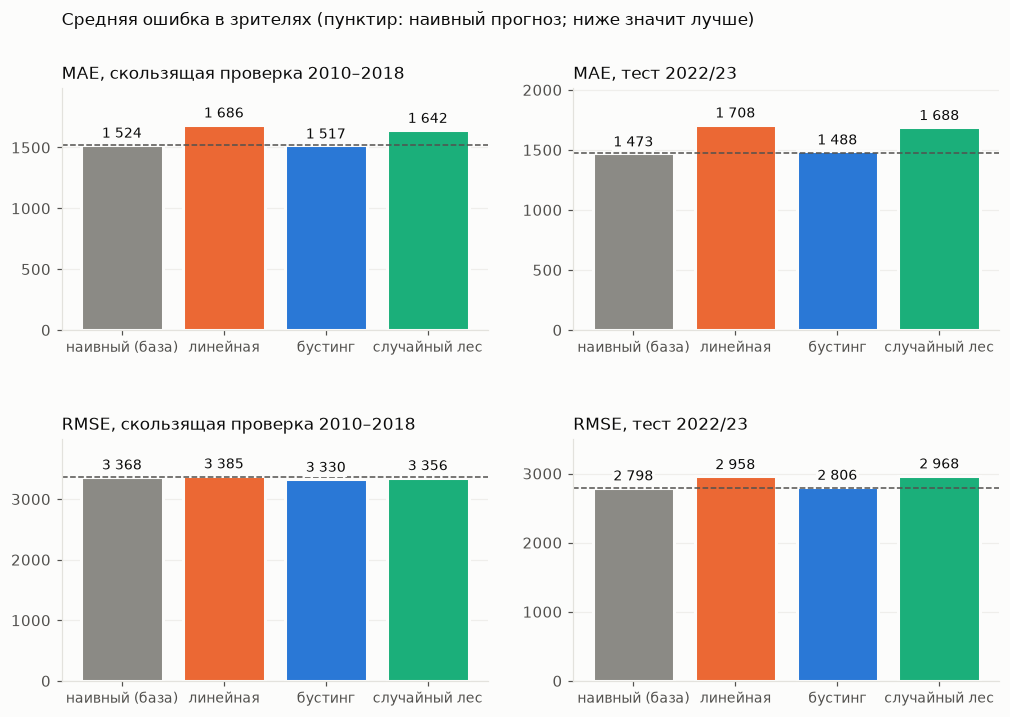

In [11]:
def bars(ax, results, key, title):
    values = {n: results[n][key] for n in MODEL_NAMES}
    ax.bar(range(4), list(values.values()), color=[COLORS[n] for n in MODEL_NAMES], edgecolor=SURFACE, linewidth=2)
    ax.axhline(values["naive"], color=INK_2, linestyle="--", linewidth=1, zorder=1)
    for i, v in enumerate(values.values()):
        ax.text(i, v * 1.02, thousands(v), ha="center", va="bottom", fontsize=9, color=INK,
                bbox={"facecolor": SURFACE, "edgecolor": "none", "pad": 1.0}, zorder=3)
    ax.set_xticks(range(4))
    ax.set_xticklabels([LABELS[n] for n in MODEL_NAMES], fontsize=9)
    ax.set_ylim(0, max(values.values()) * 1.18)
    ax.set_title(title)
    ax.grid(axis="x", visible=False)


fig, axes = plt.subplots(2, 2, figsize=(11, 7), gridspec_kw={"hspace": 0.45, "wspace": 0.2})
bars(axes[0, 0], cv_metrics, "mae", "MAE, скользящая проверка 2010–2018")
bars(axes[0, 1], test_metrics, "mae", "MAE, тест 2022/23")
bars(axes[1, 0], cv_metrics, "rmse", "RMSE, скользящая проверка 2010–2018")
bars(axes[1, 1], test_metrics, "rmse", "RMSE, тест 2022/23")
fig.suptitle("Средняя ошибка в зрителях (пунктир: наивный прогноз; ниже значит лучше)", x=0.125, ha="left", fontsize=11)
plt.show()

**Что видно.** Бустинг (`hgb`) на уровне наивного прогноза: в проверке чуть лучше по всем показателям, на тесте равен ему.
Линейная модель и случайный лес хуже базы. Для пользователя это означает: ошибка около 1,5 тысячи зрителей, примерно 4 % вместимости,
и 80 % матчей прогнозируются с ошибкой до 5 % вместимости.

## 7. Прогноз против факта

*Вопрос: где модель ошибается и стабильна ли она по сезонам?*

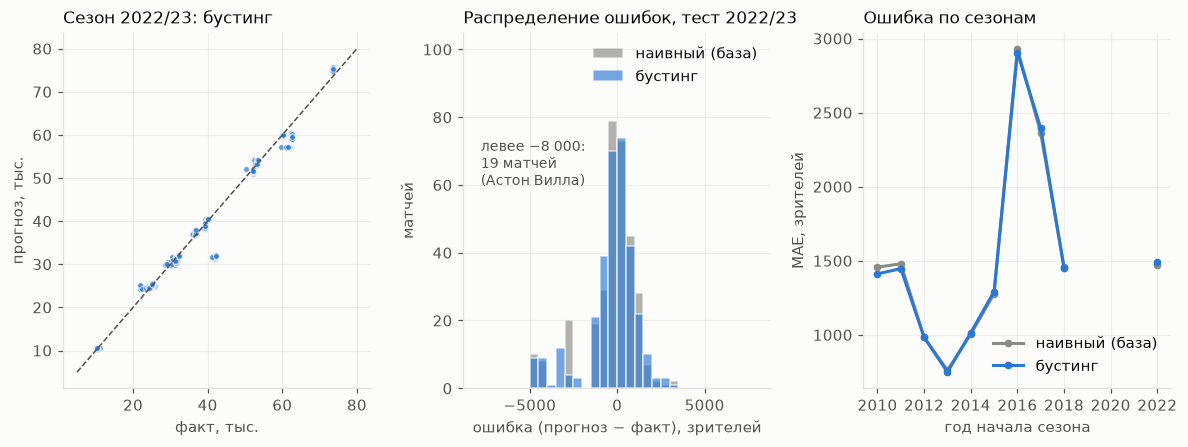

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), gridspec_kw={"wspace": 0.3})
best = test_frames["hgb"]
ax = axes[0]
ax.scatter(best.attendance / 1000, best.pred / 1000, s=14, color=BLUE, alpha=0.7, edgecolors=SURFACE, linewidths=0.6)
ax.plot([5, 80], [5, 80], color=INK_2, linestyle="--", linewidth=1)
ax.set_xlabel("факт, тыс.")
ax.set_ylabel("прогноз, тыс.")
ax.set_title("Сезон 2022/23: бустинг")

ax = axes[1]
bins = np.linspace(-8000, 8000, 33)
for name in ("naive", "hgb"):
    err = test_frames[name].pred - test_frames[name].attendance
    ax.hist(err, bins=bins, color=COLORS[name], alpha=0.65, label=LABELS[name], edgecolor=SURFACE)
outside = int(((test_frames["hgb"].pred - test_frames["hgb"].attendance) < -8000).sum())
ax.text(-7800, 60, f"левее −8 000:\n{outside} матчей\n(Астон Вилла)", color=INK_2, fontsize=9)
ax.set_ylim(0, 105)
ax.legend(frameon=False, loc="upper right")
ax.set_xlabel("ошибка (прогноз − факт), зрителей")
ax.set_ylabel("матчей")
ax.set_title("Распределение ошибок, тест 2022/23")

ax = axes[2]
for name in ("naive", "hgb"):
    frame = pd.concat([cv_frames[name], test_frames[name]])
    per_season = frame.groupby("season").apply(lambda g: (g.pred - g.attendance).abs().mean())
    per_season = per_season.reindex(range(2010, 2023))
    ax.plot(per_season.index, per_season.values, color=COLORS[name], marker="o", markersize=4, linewidth=2, label=LABELS[name])
ax.set_xticks(range(2010, 2023, 2))
ax.legend(frameon=False)
ax.set_xlabel("год начала сезона")
ax.set_ylabel("MAE, зрителей")
ax.set_title("Ошибка по сезонам")
plt.show()

Прогноз лежит около диагонали, распределения ошибок у наивного прогноза и у бустинга почти совпадают, ошибка по сезонам
у них идёт вместе. Всплески 2016–2017 годов вызваны переездами «Вест Хэма» и «Тоттенхэма» на новые стадионы: такие события по данным предсказать нельзя.

Самые большие промахи в тесте 2022/23 — «Астон Вилла» (19 матчей, ошибка около −10 тысяч): клуб вернулся в лигу, а последняя достоверная
история относится к сезону 2015/16, когда посещаемость была заметно ниже. Эта ошибка одинакова у наивного прогноза и у моделей,
то есть вызвана устаревшей историей, а не выбором модели.

## 8. Прогноз на ближайшие матчи

*Вопрос: что система прогнозирует на предстоящие туры?* Прогноз рабочей модели, рядом наивный прогноз для сравнения.

In [13]:
display(sql('''SELECT id, model_name AS модель, status AS статус, artifact_path AS артефакт FROM model_versions ORDER BY id DESC LIMIT 3'''))
forecast = sql('''SELECT m.match_date AS дата, th.name AS хозяева, ta.name AS гости, p.predicted AS прогноз, p.baseline AS наивный
                  FROM predictions p JOIN matches m ON m.id = p.match_id
                  JOIN teams th ON th.id = m.home_team_id JOIN teams ta ON ta.id = m.away_team_id
                  JOIN model_versions v ON v.id = p.model_version_id
                  WHERE v.status = 'production' AND p.kind = 'forecast' AND m.status IN ('TIMED', 'SCHEDULED')
                  ORDER BY m.match_date, th.name LIMIT 15''')
display(forecast)

,id,модель,статус,артефакт
0,3,hgb,production,hgb_v3.joblib
1,2,hgb,archived,hgb_v2.joblib
2,1,hgb,archived,hgb_v1.joblib


,дата,хозяева,гости,прогноз,наивный
0,2026-11-06,Everton,Coventry,39255,39200
1,2026-11-07,Arsenal,Hull,60249,60177
2,2026-11-07,Fulham,Newcastle,24136,24324
3,2026-11-07,Leeds,Tottenham,36229,36547
4,2026-11-07,Nottingham,Man City,29410,29293
5,2026-11-08,Brighton,Brentford,31706,31578
6,2026-11-08,Crystal Palace,Liverpool,25143,25188
7,2026-11-08,Ipswich,Bournemouth,25757,25791
8,2026-11-08,Man United,Aston Villa,73335,73431
9,2026-11-08,Sunderland,Chelsea,41101,41250


## 9. Выводы и ограничения

- **Данные.** Три источника загружаются автоматически, повторно ничего не дублируют, сбои одного источника не останавливают остальные.
  Посещаемость недостоверна в пяти сезонах, система размечает их сама.
- **Признаки.** Считаются одним кодом и для обучения, и для прогноза, утечка проверена тестами (включая искусственно внесённые утечки).
- **Модели.** Посещаемость почти целиком определяется вместимостью стадиона, поэтому наивный прогноз по истории стадиона очень силён.
  Бустинг на его уровне, остальные модели хуже. Ошибка около 1,5 тыс. зрителей (≈ 4 % вместимости).
- **Ограничения.** Переезды и расширения стадионов (в том числе «Эвертон» в 2025/26) не видны ни данным, ни модели;
  в CSV название стадиона — текущее, подставленное задним числом; для прогноза на 2026/27 последняя достоверная история относится к 2022/23;
  тестовая выборка — один сезон.